In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import scipy as sp
import matplotlib.colors as mcolors
colors = list(mcolors.TABLEAU_COLORS)
from matplotlib.lines import Line2D

# Loading and completing the velocity profile, and computing the shear velocity

In [2]:
df = pd.read_excel(r'StClairCrossSection.xlsx')
df.columns = df.iloc[35]

In [3]:
df.iloc[37:]

35,NaN,Bed Depth (meters),NaN,Shear Velocity (meters/second),Shear Stress (Pascals or Newton/meters2),NaN,Transverse Distance (y) from Left Bank (meters),NaN,Vertical Depth (z) Below Water Surface (meters),1.2,...,9.7,9.95,10.2,10.45,10.7,10.95,11.2,11.45,11.7,11.95
37,NaN,5,NaN,NaN,NaN,NaN,0,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
38,NaN,8.0176,NaN,0.0292,0.8499,NaN,25.0031,NaN,NaN,0.530535,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
39,NaN,8.185,NaN,0.0279,0.7767,NaN,26.0047,NaN,NaN,0.537504,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
40,NaN,8.47,NaN,0.0279,0.781,NaN,27.0062,NaN,NaN,0.533031,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
41,NaN,8.6868,NaN,0.0307,0.9451,NaN,28.0078,NaN,NaN,0.62535,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
677,NaN,6.0656,NaN,0.022,0.4821,NaN,664.9981,NaN,NaN,0.42005,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
678,NaN,5.7045,NaN,0.0167,0.2796,NaN,665.9997,NaN,NaN,0.258844,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
679,NaN,5.3057,NaN,0.0154,0.2364,NaN,667.0013,NaN,NaN,0.028095,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
680,NaN,4.9514,NaN,0.0152,0.2313,NaN,668.0028,NaN,NaN,0.187229,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [4]:
velocity_grid = df.set_index('Transverse Distance (y) from Left Bank (meters)')
velocity_grid = velocity_grid[[i for i in df.columns if (type(i)==np.float64 or type(i)== float) and not np.isnan(i)]].iloc[37:]
# velocity_grid = velocity_grid.reindex(df['Transverse Distance (y) from Left Bank (meters)'].iloc[37:])

In [5]:
arr_distances_lb = velocity_grid.index.astype(float).values
arr_shear_velocities = df['Shear Velocity (meters/second)'].iloc[37:].astype(float).values
arr_bed_depths = df['Bed Depth (meters)'].iloc[37:].astype(float).values
arr_depths = velocity_grid.columns.astype(float).values
arr_velocity_grid = ((velocity_grid.astype(float)).values).T


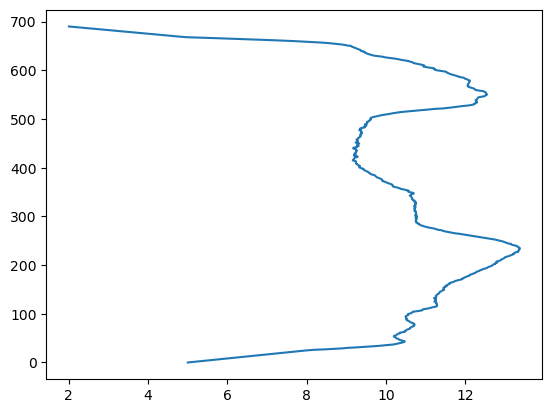

In [6]:
plt.plot(arr_bed_depths,arr_distances_lb)

Text(0.5, 0, '$y$ [m]')

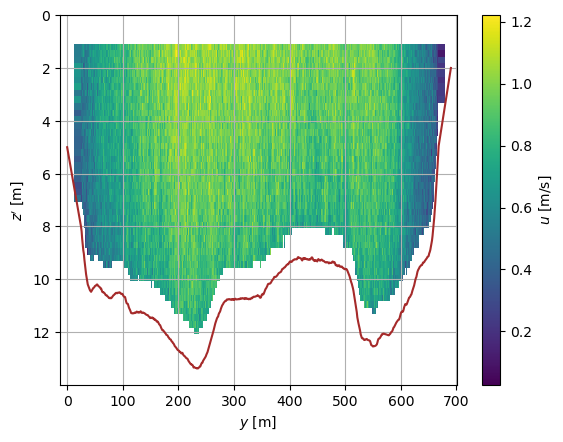

In [7]:
ax = plt.gca()
cm = ax.pcolormesh(arr_distances_lb,arr_depths,arr_velocity_grid)
ax.plot(arr_distances_lb,arr_bed_depths, c = 'brown')
cbar = plt.colorbar(cm, ax = ax)
cbar.set_label(r'$u$ [m/s]')
ax.set_ylim(0,None)
ax.yaxis.set_inverted(True)
ax.grid()
ax.set_ylabel(r"$z'$ [m]")
ax.set_xlabel(r"$y$ [m]")

In [8]:
np.nansum(arr_velocity_grid)*np.mean(np.diff(arr_depths))*np.mean(np.diff(arr_distances_lb))

np.float64(4860.932871873223)

Text(0.5, 0, '$y$ [m]')

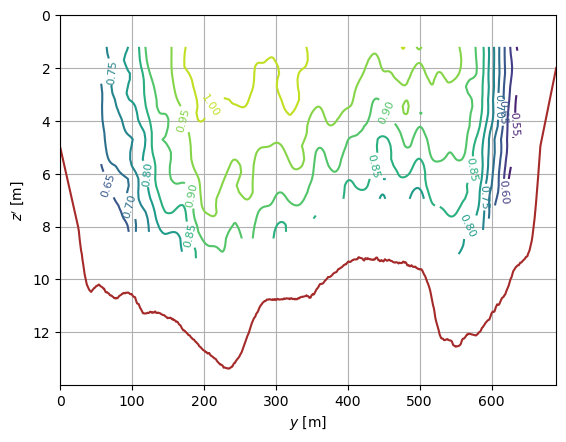

In [9]:
ax = plt.gca()
cm = ax.contour(arr_distances_lb,arr_depths,sp.ndimage.gaussian_filter(arr_velocity_grid,(1,8)), levels = 10)
# Add labels to the contour lines
plt.clabel(cm, inline=True, fontsize=8)
ax.plot(arr_distances_lb,arr_bed_depths, c = 'brown')
ax.set_ylim(0,None)
ax.yaxis.set_inverted(True)
ax.grid()
ax.set_ylabel(r"$z'$ [m]")
ax.set_xlabel(r"$y$ [m]")

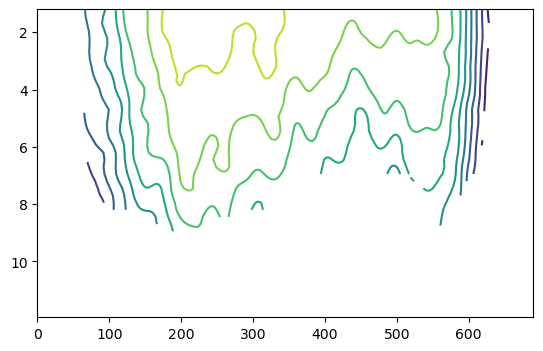

In [10]:
fig, ax = plt.subplots(1, 1, figsize=(6.4,  4))
ax.contour(arr_distances_lb,arr_depths,sp.ndimage.
gaussian_filter(arr_velocity_grid,(1,10)), levels = 10)
ax.yaxis.set_inverted(True)

C:\Users\manue\AppData\Local\Temp\ipykernel_16388\2571849361.py:24: RuntimeWarning: invalid value encountered in log
  u_star_over_k,intercept = np.polyfit(np.log(arr_bed_depths[i]-arr_depths)[~np.isnan(veloc_prof)][-n_bottom:], veloc_prof[~np.isnan(veloc_prof)][-n_bottom:], 1)
C:\Users\manue\AppData\Local\Temp\ipykernel_16388\2571849361.py:24: RuntimeWarning: divide by zero encountered in log
  u_star_over_k,intercept = np.polyfit(np.log(arr_bed_depths[i]-arr_depths)[~np.isnan(veloc_prof)][-n_bottom:], veloc_prof[~np.isnan(veloc_prof)][-n_bottom:], 1)


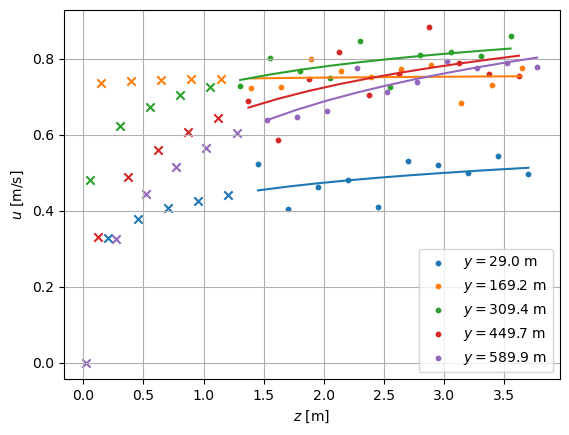

In [11]:
import matplotlib.pyplot as plt

# Access the default color cycle
prop_cycle = plt.rcParams['axes.prop_cycle']

# Extract the colors from the property cycle
tab_colors = [c['color'] for c in list(prop_cycle)]

dz = arr_depths[1]-arr_depths[0]
arr_depths_comp = np.concatenate((np.arange(arr_depths[0],0,-dz)[1:][::-1],np.arange(arr_depths[0],np.max(arr_bed_depths),dz)))
arr_velocity_grid_comp = np.empty((len(arr_depths_comp),arr_velocity_grid.shape[1]))
arr_velocity_grid_comp[np.isin(arr_depths_comp, arr_depths)] = arr_velocity_grid.copy()
arr_velocity_grid_comp[~np.isin(arr_depths_comp, arr_depths)] = np.nan


n_bottom = 10
kappa = 0.41
u_stars = []
for i in range(arr_velocity_grid.shape[1]):
    veloc_prof = arr_velocity_grid[:,i]
    if sum(np.isnan(veloc_prof))==len(veloc_prof):
        u_stars.append(np.nan)
    else:
        u_star_over_k,intercept = np.polyfit(np.log(arr_bed_depths[i]-arr_depths)[~np.isnan(veloc_prof)][-n_bottom:], veloc_prof[~np.isnan(veloc_prof)][-n_bottom:], 1)
        if u_star_over_k<0:
            u_star_over_k = 0
            intercept = np.mean(veloc_prof[~np.isnan(veloc_prof)][-n_bottom:])
        u_star = u_star_over_k*kappa
        u_stars.append(u_star)
        mask_comp_bottom = np.isnan(arr_velocity_grid_comp[:,i])&(arr_depths_comp<arr_bed_depths[i])&(arr_depths_comp>np.min(arr_depths))
        arr_velocity_grid_comp[:,i][mask_comp_bottom] = np.maximum(intercept+np.log(arr_bed_depths[i]-arr_depths_comp[mask_comp_bottom])*u_star_over_k,0)
    if i%140 == 5:
        plt.scatter(arr_bed_depths[i]-arr_depths[~np.isnan(veloc_prof)][-n_bottom:],veloc_prof[~np.isnan(veloc_prof)][-n_bottom:],label = r'$y=$'+str(round(arr_distances_lb[i],1))+' m',c = tab_colors[i//140], s = 10)
        plt.plot(arr_bed_depths[i]-arr_depths[~np.isnan(veloc_prof)][-n_bottom:],intercept+np.log(arr_bed_depths[i]-arr_depths[~np.isnan(veloc_prof)][-n_bottom:])*u_star_over_k,c = tab_colors[i//140])
        plt.scatter(arr_bed_depths[i]-arr_depths_comp[mask_comp_bottom],arr_velocity_grid_comp[:,i][mask_comp_bottom], marker = 'x',c = tab_colors[i//140])
    # print(u_star)
    # print(int(((i+0.5)*arr_velocity_grid.shape[1])//6))
# plt.xscale('log')
plt.legend(ncols = 1)
plt.xlabel('$z$ [m]')
plt.ylabel('$u$ [m/s]')
plt.grid()

Text(0.5, 0, '$y$ [m]')

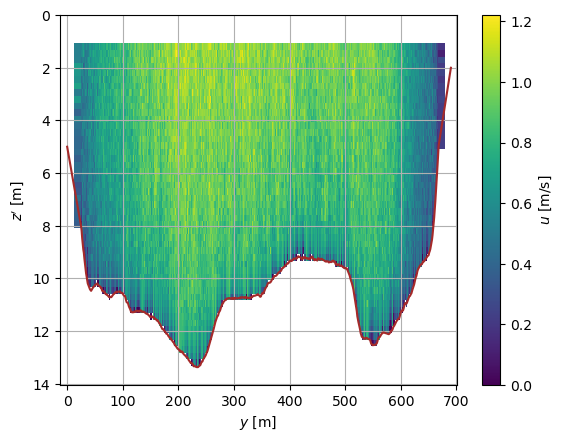

In [12]:
ax = plt.gca()
cm = ax.pcolormesh(arr_distances_lb,arr_depths_comp,arr_velocity_grid_comp)
ax.plot(arr_distances_lb,arr_bed_depths, c = 'brown')
cbar = plt.colorbar(cm, ax = ax)
cbar.set_label(r'$u$ [m/s]')
ax.set_ylim(0,None)
ax.yaxis.set_inverted(True)
ax.grid()
ax.set_ylabel(r"$z'$ [m]")
ax.set_xlabel(r"$y$ [m]")

In [13]:
coles_u = lambda z,umax,ustar,W0,H: umax+ustar/kappa*np.log(z/H)-2*W0*ustar/kappa*np.cos(np.pi*z/(2*H))**2

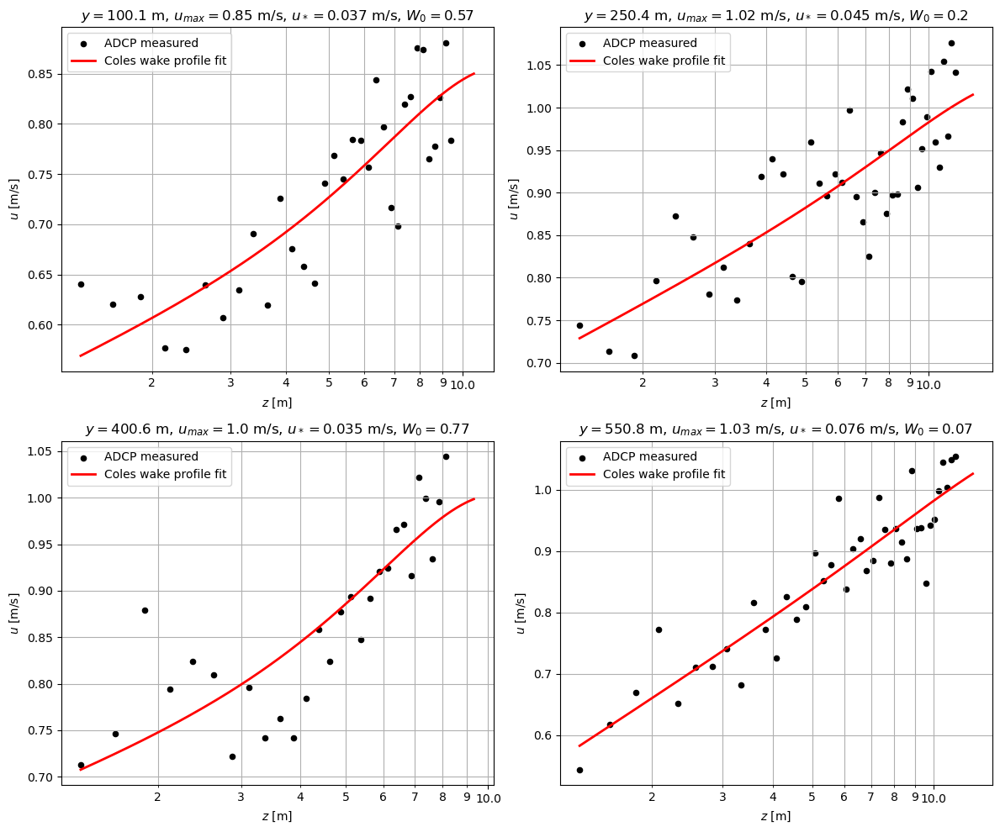

In [14]:
import matplotlib.ticker as mticker
from scipy.optimize import least_squares

# ---- choose 4 random positions i for plotting ----
plot_indices = np.arange(1, arr_velocity_grid.shape[1]-1,(arr_velocity_grid.shape[1]-2)//(8.5))[1::2]

# container for fitted parameters
params_coles = np.zeros((arr_velocity_grid.shape[1], 3))
umaxes = np.zeros(arr_velocity_grid.shape[1])
# prepare figure
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.ravel()

plot_counter = 0

for i in range(1, arr_velocity_grid.shape[1]-1):

    # extract data
    us = arr_velocity_grid[:, i]
    zs = (arr_bed_depths[i] - arr_depths)[~np.isnan(us)]
    us = us[~np.isnan(us)]
    u_max_prior = np.max(us)
    umaxes[i] = u_max_prior
    ustar_prior = u_stars[i]
    W0_prior = 0.16

    # skip empty profiles
    if len(us) < 3:
        continue

    # ---- fit Coles profile ----
    umax, ustar, W0 = least_squares(
        lambda params: np.concatenate((
            us - coles_u(zs, params[...,0], params[...,1], params[...,2], arr_bed_depths[i]),
            [(params[...,0]-u_max_prior),(params[...,1] - ustar_prior), 0.1 * (params[...,2]-W0_prior)]
        )),
        np.array([u_max_prior,           # initial guess for umax
                  ustar_prior,          # initial guess for ustar
                  W0_prior])                 # initial guess for W0
    ).x

    # store fitted results
    params_coles[i] = umax, ustar, W0

    # ---- plotting for 4 random locations ----
    if i in plot_indices:

        ax = axes[plot_counter]

        # scatter measured data
        ax.scatter(zs, us, color="black", s=20, label="ADCP measured")

        # plot fitted profile
        z_plot = np.linspace(zs.min(), arr_bed_depths[i], 200)
        ax.plot(z_plot,
                coles_u(z_plot, umax, ustar, W0, arr_bed_depths[i]),
                color="red", lw=2, label="Coles wake profile fit")

        # formatting
        ax.set_xscale("log")
        ax.set_xlabel("$z$ [m]")
        ax.set_ylabel("$u$ [m/s]")
        ax.set_title(rf"$y = {round(arr_distances_lb[i],1)}$ m, $u_{{max}} = {round(umax,2)}$ m/s, $u_*={round(ustar,3)}$ m/s, $W_0 = {round(W0,2)}$")
        ax.legend()
        ax.grid(which = 'both')
        ax.xaxis.set_minor_formatter(mticker.ScalarFormatter())
        ax.xaxis.set_major_formatter(mticker.ScalarFormatter())
        plot_counter += 1

plt.tight_layout()
plt.show()


In [15]:
for i in range(arr_distances_lb.shape[0]):
    umax, ustar, W0 = params_coles[i, 0], params_coles[i, 1], params_coles[i, 2]
    H = arr_bed_depths[i]

    # Skip if bed depth is NaN or if Coles parameters are invalid (e.g., from failed fit)
    if np.isnan(H) or np.isnan(umax) or np.isnan(ustar) or np.isnan(W0) or umax == 0.0 or ustar == 0.0:
        continue

    # Calculate depths relative to the bed (z_rel > 0 means inside the water column, positive upwards)
    z_rel = H - arr_depths_comp

    # Mask for valid depths within the water column (from water surface to bed)
    # Ensure z_rel is positive for log function in coles_u
    # Also, ensure we only replace NaN values in arr_velocity_grid_comp
    mask_valid_depths = (z_rel > 0) & (arr_depths_comp >= 0) & (arr_depths_comp < H)
    mask_nan_in_grid = np.isnan(arr_velocity_grid_comp[:, i])
    final_mask = mask_valid_depths & mask_nan_in_grid

    if np.any(final_mask):
        # Calculate velocities using the Coles wake profile for the valid depths
        fitted_velocities = coles_u(z_rel[final_mask], umax, ustar, W0, H)

        # Ensure velocities are non-negative
        fitted_velocities[fitted_velocities < 0] = 0

        # Fill the arr_velocity_grid_comp with these fitted values
        arr_velocity_grid_comp[final_mask, i] = fitted_velocities

Text(0.5, 0, '$y$ [m]')

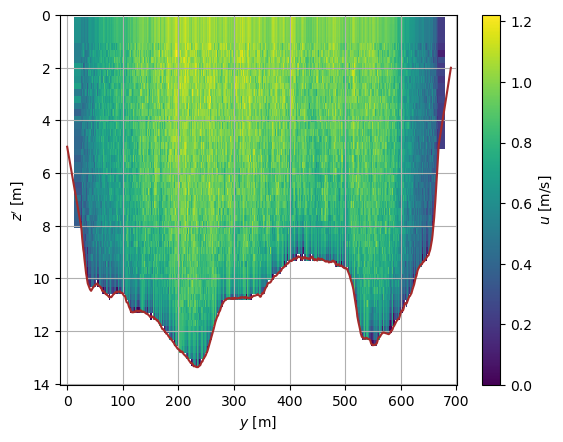

In [16]:
ax = plt.gca()
cm = ax.pcolormesh(arr_distances_lb,arr_depths_comp,arr_velocity_grid_comp)
ax.plot(arr_distances_lb,arr_bed_depths, c = 'brown')
cbar = plt.colorbar(cm, ax = ax)
cbar.set_label(r'$u$ [m/s]')
ax.set_ylim(0,None)
ax.yaxis.set_inverted(True)
ax.grid()
ax.set_ylabel(r"$z'$ [m]")
ax.set_xlabel(r"$y$ [m]")

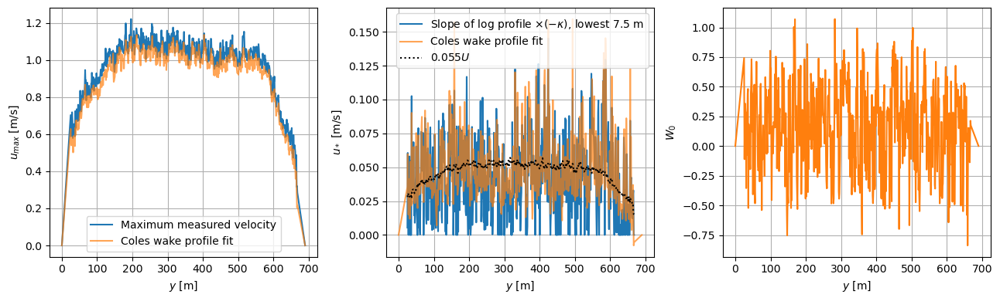

In [17]:
fig, axes = plt.subplots(1,3, figsize=(13, 4))
axes[0].plot(arr_distances_lb,umaxes,label = 'Maximum measured velocity')
axes[0].plot(arr_distances_lb,params_coles[:,0],alpha = 0.7,label = "Coles wake profile fit")
axes[0].set_xlabel("$y$ [m]")
axes[0].set_ylabel('$u_{max}$ [m/s]')
axes[0].legend()
axes[0].grid()

axes[1].plot(arr_distances_lb,u_stars,alpha = 1.0,label = r'Slope of log profile $\times(-\kappa)$, lowest 7.5 m')
axes[1].plot(arr_distances_lb,params_coles[:,1],alpha = 0.7,label = "Coles wake profile fit")
axes[1].plot(arr_distances_lb,arr_shear_velocities, c = 'k', linestyle = 'dotted', label='$0.055 U$')
axes[1].set_xlabel("$y$ [m]")
axes[1].set_ylabel('$u_*$ [m/s]')
axes[1].legend()
axes[1].grid()

axes[2].plot(arr_distances_lb,params_coles[:,2], color = 'tab:orange')
axes[2].set_xlabel("$y$ [m]")
axes[2].set_ylabel('$W_0$')
axes[2].grid()

fig.tight_layout()

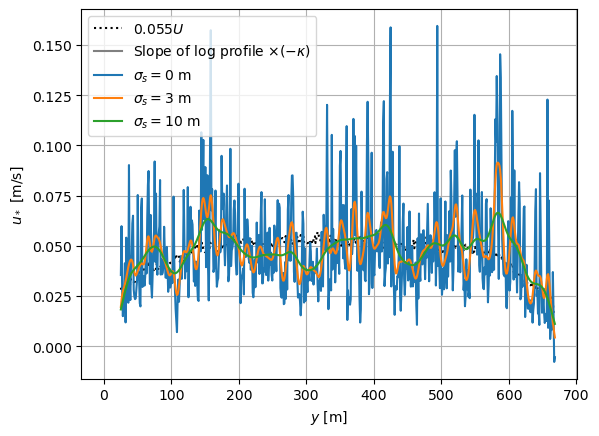

In [18]:
plt.plot(arr_distances_lb,arr_shear_velocities, c = 'k', linestyle = 'dotted', label='$0.055 U$')
plt.plot([0],[0], c = 'gray', label = r'Slope of log profile $\times(-\kappa)$')
for gaussian_smoothing in [0,3,10]:
    u_stars_smooth = sp.ndimage.gaussian_filter(params_coles[:,1][1:-1],gaussian_smoothing,mode = 'constant')
    plt.plot(arr_distances_lb[1:-1],u_stars_smooth, label = fr'$\sigma_{{s}} = {gaussian_smoothing}$ m')

plt.xlabel("$y$ [m]")
plt.ylabel('$u_*$ [m/s]')
plt.legend()
plt.grid()

Text(0.5, 0, '$y$ [m]')

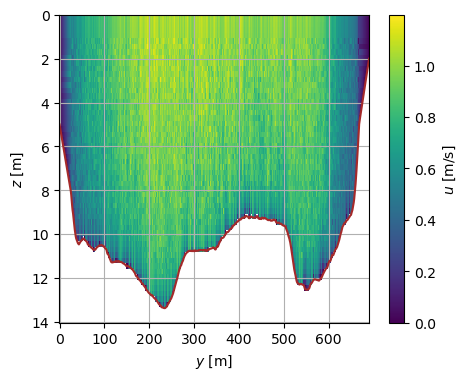

In [19]:
arr_distances_lb_unif = np.linspace(arr_distances_lb[0],arr_distances_lb[-1],int(round(arr_distances_lb[-1]-arr_distances_lb[0])/np.median(np.diff(arr_distances_lb))))
arr_bed_depths_unif = np.interp(arr_distances_lb_unif,arr_distances_lb,arr_bed_depths)
arr_velocity_grid_unif = np.array([np.interp(arr_distances_lb_unif,
                                         np.concatenate(([arr_distances_lb_unif[np.where(arr_depths_comp[i]<arr_bed_depths_unif)[0][0]]],
                                                         arr_distances_lb[~np.isnan(arr_velocity_grid_comp[i])],
                                                          [arr_distances_lb_unif[np.where(arr_depths_comp[i]<arr_bed_depths_unif)[0][-1]]])),
                                         np.concatenate(([0],arr_velocity_grid_comp[i][~np.isnan(arr_velocity_grid_comp[i])],[0]))) for i in range(len(arr_velocity_grid_comp))])
u_stars_unif = np.interp(arr_distances_lb_unif,arr_distances_lb,np.nan_to_num(u_stars,nan = 0))
arr_velocity_grid_unif[arr_depths_comp[:,None]>arr_bed_depths_unif] = np.nan
fig,ax = plt.subplots(figsize=(5,4))
cm = ax.pcolormesh(arr_distances_lb_unif,arr_depths_comp,arr_velocity_grid_unif)
ax.plot(arr_distances_lb_unif,arr_bed_depths_unif, c = 'brown')
cbar = plt.colorbar(cm, ax = ax)
cbar.set_label(r'$u$ [m/s]')
ax.set_ylim(0,None)
ax.yaxis.set_inverted(True)
ax.grid()
ax.set_ylabel(r"$z$ [m]")
ax.set_xlabel(r"$y$ [m]")

# Eigenvalue problem

In [20]:
gaussian_smoothing = 10
u_star_h = sp.ndimage.gaussian_filter(u_stars_unif,gaussian_smoothing,mode = 'constant')*arr_bed_depths_unif
D_y_fac = 0.6
D_y = D_y_fac*u_star_h
D_z = 0.067*u_star_h
b = arr_distances_lb_unif[-1]-arr_distances_lb[0]

dz = np.mean(np.diff(arr_depths))/b
dy = np.mean(np.diff(arr_distances_lb_unif))/b
D_ref = np.mean(D_y)

u_array = arr_velocity_grid_unif.copy()

psi_y = u_array.copy()
psi_z = u_array.copy()
for i in range(len(D_y)):
    psi_y[:,i][~np.isnan(psi_y[:,i])] = D_y[i]/D_ref
    psi_z[:,i][~np.isnan(psi_z[:,i])] = D_z[i]/D_ref
psi_x = psi_y
dt = 0.45 / (
    np.nanmax(psi_y)/dy**2 +
    np.nanmax(psi_z)/dz**2
)
chi = u_array/np.nanmean(u_array)-1
mu = np.nanmean(u_array)*b/D_ref

In [21]:
from scipy.sparse import lil_matrix
from scipy.sparse.linalg import eigsh

def build_diffusion_operator(
    psi_y, psi_z, mask,
    dy, dz,
    face_mean="harmonic"
):
    Ny, Nz = psi_y.shape

    idx = -np.ones((Ny, Nz), dtype=int)
    active = np.where(mask)
    idx[active] = np.arange(len(active[0]))
    N = len(active[0])

    L = lil_matrix((N, N))
    eps = 1e-30

    def face_coeff(a, b):
        if face_mean == "arithmetic":
            return 0.5 * (a + b)
        elif face_mean == "harmonic":
            return 2*a*b / (a + b + eps)
        else:
            raise ValueError

    for i, j in zip(*active):
        p = idx[i, j]
        diag = 0.0

        # ---- y+ ----
        if i+1 < Ny and mask[i+1, j]:
            q = idx[i+1, j]
            psi = face_coeff(psi_y[i, j], psi_y[i+1, j])
            w = psi / dy**2
            L[p, q] += w
            diag -= w

        # ---- y- ----
        if i-1 >= 0 and mask[i-1, j]:
            q = idx[i-1, j]
            psi = face_coeff(psi_y[i-1, j], psi_y[i, j])
            w = psi / dy**2
            L[p, q] += w
            diag -= w

        # ---- z+ ----
        if j+1 < Nz and mask[i, j+1]:
            q = idx[i, j+1]
            psi = face_coeff(psi_z[i, j], psi_z[i, j+1])
            w = psi / dz**2
            L[p, q] += w
            diag -= w

        # ---- z- ----
        if j-1 >= 0 and mask[i, j-1]:
            q = idx[i, j-1]
            psi = face_coeff(psi_z[i, j-1], psi_z[i, j])
            w = psi / dz**2
            L[p, q] += w
            diag -= w

        L[p, p] += diag

    return L.tocsr(), idx


In [27]:
# build operator
L, idx = build_diffusion_operator(
    psi_y.T, psi_z.T,
    mask=(~np.isnan(psi_y.T)),
    dy=dy,
    dz=dz,
    face_mean="harmonic"
)

w = 1/L.shape[0]

Ny, Nz = psi_y.T.shape
c1_lim_vec = sp.sparse.linalg.spsolve(L,-mu*chi.T[idx >= 0])
c1_lim_phys = np.full((Ny, Nz), np.nan)
c1_lim_phys[idx >= 0] = c1_lim_vec
K_lim = np.nanmean(psi_x.T)+mu*np.nansum(chi.T*c1_lim_phys*w)
print('Asymptotic K,',K_lim*D_ref)

A = np.trapezoid(arr_bed_depths_unif,x = arr_distances_lb_unif)
u_ver_avg = np.nanmean(u_array,axis = 0)
u_prime = u_ver_avg-np.nanmean(u_array)
K_lim_integrals = -1/A*np.trapezoid(u_prime*arr_bed_depths_unif*
         sp.integrate.cumulative_trapezoid(1/(D_y*arr_bed_depths_unif)*
         sp.integrate.cumulative_trapezoid(u_prime*arr_bed_depths_unif,x=arr_distances_lb_unif,initial=0.0),x=arr_distances_lb_unif,initial=0.0),x=arr_distances_lb_unif)

H = np.mean(arr_bed_depths_unif)
u_star_mean = (np.nanmean(u_star_h)/np.nanmean(arr_bed_depths_unif))
U = np.nanmean(u_array)
print('Mean channel velocity,',U)

epsilon_t0 = 0.145+1/3520*(U/u_star_mean)*(b/H)*1.38
K_pred_Deng = 1/(8*epsilon_t0)*0.01/(b/H)**(1/3)
nu = 10**(-6)

Re = U*H/nu
g = 9.81
Fr = U/np.sqrt(g*H)
print("Reynolds number,",Re)
print("Froude number,",Fr)

Deng_corr =5.999*10**7 * Re**(-1.054) * (u_star_mean/U)**(-1.781) * (b/H)**(-1.391)

print('Asymptotic K, integrated using 1D formula,',K_lim_integrals)
print('Asymptotic K, predicted by Deng,',(np.nanmean(arr_velocity_grid_comp)*b)**2/D_ref*K_pred_Deng+D_ref)
print('Asymptotic K, predicted by Deng with data-driven psi,',(np.nanmean(arr_velocity_grid_comp)*b)**2/D_ref*Deng_corr*K_pred_Deng+D_ref)
print('1D integration over Deng',K_lim_integrals/((np.nanmean(arr_velocity_grid_comp)*b)**2/D_ref*K_pred_Deng+D_ref))
print('Exact value over Deng',K_lim*D_ref/((np.nanmean(arr_velocity_grid_comp)*b)**2/D_ref*K_pred_Deng+D_ref))
print('Data driven Deng psi',Deng_corr)

print('Asymptotic K, assuming 1D power law velocity profile and constant coefficients, for different values of the exponent')
for n in range(1,10):
  coefficient = 3*(n+3)**2+9*(n+1)*(n+3) # From computing the integral with constant coefficients like in https://doi.org/10.1029/2011GL050831, I have a desmos file where I do it. No need for them to be integers.
  print('     ',n,(np.nanmean(arr_velocity_grid_comp)*b)**2/D_ref/coefficient+D_ref)

Asymptotic K, 928.7812854779905
Mean channel velocity, 0.7888815196179334
Reynolds number, 8189537.898303174
Froude number, 0.07817240463752968
Asymptotic K, integrated using 1D formula, 908.2342708396753
Asymptotic K, predicted by Deng, 581.0823289287962
Asymptotic K, predicted by Deng with data-driven psi, 995.0049857158193
1D integration over Deng 1.5630044584456244
Exact value over Deng 1.5983643611915794
Data driven Deng psi 1.7126476782188147
Asymptotic K, assuming 1D power law velocity profile and constant coefficients, for different values of the exponent
      1 10039.754440490502
      2 5737.113381082259
      3 3718.5904149401204
      4 2607.9198833308096
      5 1930.93090545189
      6 1487.5913470988091
      7 1181.3757887676488
      8 960.9759371458363
      9 797.0440165764986


In [23]:
np.nansum(u_array)*dz*dy*b**2

np.float64(5625.738471913518)

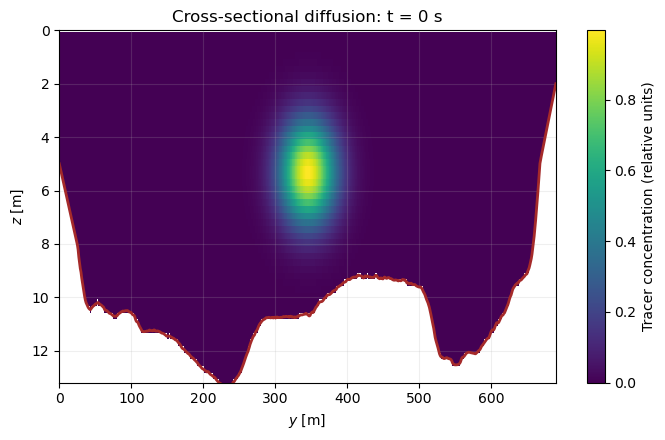

In [24]:

import numpy as np
import scipy.sparse.linalg as spla
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation

# ------------------------------------------------------------
# 1. Construct the cross-sectional diffusion operator
# ------------------------------------------------------------
# Arrays are originally arranged as (z, y).
# The operator uses (y, z).

y = arr_distances_lb_unif
z = arr_depths_comp
bed = arr_bed_depths_unif

Ny = len(y)
Nz = len(z)

# Dimensionless spatial increments
dy = np.mean(np.diff(y)) / b
dz = np.mean(np.diff(z)) / b

# Wet cells: z <= local bed depth
mask_zy = z[:, None] <= bed[None, :]
mask = mask_zy.T  # (y, z)

# Dimensionless diffusion coefficients, varying across y
D_ref_anim = np.mean(D_y)

psi_y_anim = np.broadcast_to(
    (D_y / D_ref_anim)[None, :], (Nz, Ny)
).copy()

psi_z_anim = np.broadcast_to(
    (D_z / D_ref_anim)[None, :], (Nz, Ny)
).copy()

L_anim, idx_anim = build_diffusion_operator(
    psi_y_anim.T,
    psi_z_anim.T,
    mask=mask,
    dy=dy,
    dz=dz,
    face_mean="harmonic"
)

# Stable explicit time step in dimensionless time:
# tau = t * D_ref_anim / b**2
dtau = 0.4 / (
    np.max(D_y / D_ref_anim) / dy**2
    + np.max(D_z / D_ref_anim) / dz**2
)

# ------------------------------------------------------------
# 2. Initial tracer release
# ------------------------------------------------------------
# Release location: adjust these to move the initial plume.
y0 = y[Ny // 2]
z0 = 0.5 * bed[Ny // 2]

# Initial plume widths in physical coordinates [m]
sigma_y = 0.04 * (y[-1] - y[0])
sigma_z = 0.10 * np.max(bed)

Y, Z = np.meshgrid(y, z)

C0 = np.exp(
    -0.5 * ((Y - y0) / sigma_y)**2
    -0.5 * ((Z - z0) / sigma_z)**2
)
C0[~mask_zy] = np.nan

# Pack wet cells into the sparse-operator ordering
C = C0.T[idx_anim >= 0].copy()

# ------------------------------------------------------------
# 3. Animation settings
# ------------------------------------------------------------
steps_per_frame = 50
n_frames = 200

# Dimensionless diffusion time between displayed frames
frame_dtau = steps_per_frame * dtau

# Physical time represented by each frame [s]
frame_dt = frame_dtau * b**2 / D_ref_anim

# Fixed color scale for the whole animation
vmin = 0.0
vmax = np.nanmax(C0)

fig, ax = plt.subplots(figsize=(7, 4.5))

cm = ax.pcolormesh(
    y, z, C0,
    shading="auto",
    cmap="viridis",
    vmin=vmin,
    vmax=vmax
)

ax.plot(y, bed, color="brown", lw=2)
ax.set_xlim(y[0], y[-1])
ax.set_ylim(np.max(z), 0)
ax.set_xlabel(r"$y$ [m]")
ax.set_ylabel(r"$z$ [m]")
ax.grid(alpha=0.2)

cbar = fig.colorbar(cm, ax=ax)
cbar.set_label("Tracer concentration (relative units)")

time_label = ax.set_title("Cross-sectional diffusion: t = 0 s")

# ------------------------------------------------------------
# 4. Advance the diffusion equation and animate
# ------------------------------------------------------------

def update(frame):
    global C

    for _ in range(steps_per_frame):
        C = C + dtau * (L_anim @ C)

    C_phys = np.full((Ny, Nz), np.nan)
    C_phys[idx_anim >= 0] = C

    # Update concentration field
    cm.set_array(C_phys.T.ravel())

    # Dynamic color scale at every frame
    valid = C_phys[np.isfinite(C_phys)]
    cmin = valid.min()
    cmax = valid.max()

    cm.set_clim(cmin, cmax)

    # Update colorbar to reflect the changing scale
    cbar.update_normal(cm)

    t_hours = (frame + 1) * frame_dt / 3600
    time_label.set_text(
        f"Cross-sectional diffusion: t = {t_hours:.4g} h"
    )

    return cm, time_label


ani = FuncAnimation(
    fig,
    update,
    frames=n_frames,
    interval=40,
    blit=False
)

plt.tight_layout()
plt.show()


In [33]:
%%time
from IPython.display import HTML, display

plt.close(fig)
display(HTML(ani.to_jshtml()))

CPU times: total: 32.2 s
Wall time: 32.8 s


In [25]:

ani.save(
    "cross_section_diffusion.gif",
    writer="pillow",
    fps=25,
    dpi=100
)

In [53]:
%%time
# smallest-magnitude eigenvalues = slowest modes
N = 30
vals, vecs = eigsh(L, k=N, which="SM")

vecs = vecs / np.sqrt(w)
order = np.argsort(np.abs(vals))
vals = vals[order]
vecs = vecs[:, order]
vals[0] = 0
print("Eigenvalues:")
for i, lam in enumerate(vals):
    print(f"mode {i}: λ = {lam:.5e}")

Eigenvalues:
mode 0: λ = 0.00000e+00
mode 1: λ = -1.07800e+01
mode 2: λ = -4.72459e+01
mode 3: λ = -5.95140e+01
mode 4: λ = -9.99873e+01
mode 5: λ = -1.58344e+02
mode 6: λ = -1.93456e+02
mode 7: λ = -2.49034e+02
mode 8: λ = -2.94960e+02
mode 9: λ = -3.10264e+02
mode 10: λ = -3.88184e+02
mode 11: λ = -5.10549e+02
mode 12: λ = -5.80163e+02
mode 13: λ = -6.22629e+02
mode 14: λ = -6.61977e+02
mode 15: λ = -6.97605e+02
mode 16: λ = -8.23911e+02
mode 17: λ = -8.35522e+02
mode 18: λ = -9.29303e+02
mode 19: λ = -1.04426e+03
mode 20: λ = -1.11441e+03
mode 21: λ = -1.18693e+03
mode 22: λ = -1.38215e+03
mode 23: λ = -1.45242e+03
mode 24: λ = -1.49306e+03
mode 25: λ = -1.54600e+03
mode 26: λ = -1.54722e+03
mode 27: λ = -1.62602e+03
mode 28: λ = -1.68659e+03
mode 29: λ = -1.73500e+03
CPU times: total: 29.1 s
Wall time: 11.6 s


In [54]:
modes = np.full((N, Ny, Nz), np.nan)

for m in range(N):
    v = vecs[:, m]
    modes[m][idx >= 0] = v

c00_phys_dist = chi.T.copy()
c00_phys_dist[~np.isnan(c00_phys_dist)] = 1.0
c00_vec_dist = c00_phys_dist[idx >= 0]

c00_phys_loc = chi.T.copy()
c00_phys_loc[~np.isnan(c00_phys_loc)] = 0.0
index_IC = np.unravel_index(np.nanargmin(np.meshgrid(np.arange(Nz),np.arange(Ny))[0]*(c00_phys_loc+1)
                +np.abs(np.meshgrid(np.arange(Nz),np.arange(Ny))[1]*(c00_phys_loc+1)-Ny//2)),c00_phys_loc.shape)
c00_phys_loc[index_IC] = vecs.shape[0]
c00_vec_loc = c00_phys_loc[idx >= 0]

a0_dist =  vecs.T @ (w *c00_vec_dist)
a0_loc =  vecs.T @ (w *c00_vec_loc)

dm1_coeffs_dist = np.nansum(a0_dist[:,None,None]*w*modes*(chi+1).T[None,:,:],axis = (1,2))
dm1_coeffs_loc = np.nansum(a0_loc[:,None,None]*w*modes*(chi+1).T[None,:,:],axis = (1,2))

Nt = 400
ts = np.linspace(0,0.4,Nt)

v_eff_dist = np.nansum(np.exp(vals[:,None]*ts[1:])*dm1_coeffs_dist[:,None],axis = 0)
v_eff_loc = np.nansum(np.exp(vals[:,None]*ts[1:])*dm1_coeffs_loc[:,None],axis = 0)

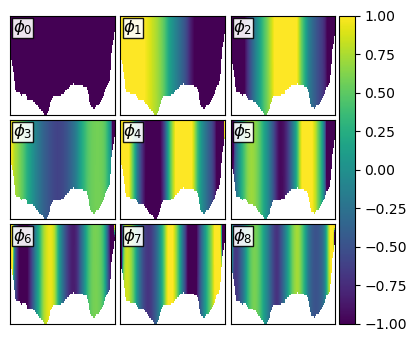

In [55]:
fig,axes = plt.subplots(figsize=(5,4),ncols = 3, nrows = 3)
axes = axes.flatten()
for i in range(9):
    im = axes[i].pcolormesh(modes[i].T[::-1],vmin = -1 ,vmax = 1)
    axes[i].set_xticks([])
    axes[i].set_yticks([])
    axes[i].set_title(fr'$\phi_{{{i}}}$', y=1.0, pad=-12,x = 0.12, bbox={'facecolor':'white', 'alpha':0.9, 'pad': 0.4})
plt.subplots_adjust(wspace=0.05, hspace=0.05)
fig.colorbar(im, ax=axes, orientation='vertical', pad = 0.01)

# Reduction of number of modes

In [56]:
chi_vec = chi.T[idx>=0]
N_ = 20
args_sign = np.concatenate(([0],np.argsort(np.abs((-mu**2*(vecs.T@(chi_vec*w))**2/vals)[1:]))[::-1][:N_-1]+1))
vecs_ = vecs[:,args_sign]
vals_ = vals[args_sign]
M_1 = vecs_.T@(vecs_*psi_x.T[idx >= 0][:,None]*w)
M_2 = vecs_.T@(vecs_*(chi).T[idx >= 0][:,None]*w)
M_2_adv = vecs_.T@(vecs_*(chi+1).T[idx >= 0][:,None]*w)
dm1_coeffs_dist_,dm1_coeffs_loc_ = dm1_coeffs_dist[args_sign], dm1_coeffs_loc[args_sign] 
a0_dist_,a0_loc_ = a0_dist[args_sign], a0_loc[args_sign] 

C:\Users\Manuel\AppData\Local\Temp\ipykernel_19192\2590899708.py:3: RuntimeWarning: divide by zero encountered in divide
  args_sign = np.concatenate(([0],np.argsort(np.abs((-mu**2*(vecs.T@(chi_vec*w))**2/vals)[1:]))[::-1][:N_-1]+1))


# Function

In [57]:
# This is a python translation of the program written by Hollenbeck, K. J. (1998)
#
# DEHOOG - numerical inverse Laplace transform
#
# Description: 
#   algorithm: de Hoog et al's quotient difference method with accelerated 
#   convergence for the continued fraction expansion
#
#   [de Hoog, F. R., Knight, J. H., and Stokes, A. N. (1982). An improved 
#   method for numerical inversion of Laplace transforms. S.I.A.M. J. Sci. 
#   and Stat. Comput., 3, 357-366.]
#
#   Modification: The time vector is split in segments of equal magnitude
#   which are inverted individually. This gives a better overall accuracy.   
#
#   Details: de Hoog et al's algorithm f4 with modifications (T->2*T and 
#    introduction of tol). Corrected error in formulation of z.
#
#   Copyright: Karl Hollenbeck
#             Department of Hydrodynamics and Water Resources
#             Technical University of Denmark, DK-2800 Lyngby
#             email: karl@isv16.isva.dtu.dk
#
#   22 Nov 1996, MATLAB 5 version 27 Jun 1997 updated 1 Oct 1998
#   IF YOU PUBLISH WORK BENEFITING FROM THIS M-FILE, PLEASE CITE IT AS:
#       Hollenbeck, K. J. (1998) INVLAP.M: A matlab function for numerical 
#       inversion of Laplace transforms by the de Hoog algorithm, 
#       http://www.isva.dtu.dk/staff/karl/invlap.htm 
#
#   Renamed by P. Renard to be integrated in the hytool toolbox.
#
# example: 
#   identity function in Laplace space:
#   F = lambda s: 1/(s**2)        
#   invlap(F, np.array([1,2,3]))                # gives [1,2,3]
#
# See also: stefhest
#

import numpy as np 
import warnings

warnings.filterwarnings('ignore', 'overflow')
warnings.filterwarnings('ignore', 'invalid')
warnings.filterwarnings('ignore', 'divide')

def invlap(F, t,args, alpha=0.0, tol=1e-10,M = 400):
    """
    F      = laplace-space function (string refering to an m-file),must
             have form F(s, args), where s is the Laplace parameter 
             and return column vector as result
    t      = column vector of times for which real-space function values
             are sought
    args   = other parameters of F
    alpha  = largest pole of F (default zero)
    tol    = numerical tolerance of approaching pole (default 1e-10)
    f      = vector of real-space values f(t)   
    """
    f = []
    # Split up t vector in pieces of the same order of magnitude, invert one piece
    # at a time. Simultaneous inversion for times covering several orders of
    # magnitudes gives inaccurate results for the small times.
    allt = t
    logallt = np.log(allt)
    iminlogallt = int(np.floor(np.min(logallt)))
    imaxlogallt = int(np.ceil(np.max(logallt)))

    for ilogt in range(iminlogallt, imaxlogallt + 1):
        t = allt[(logallt >= ilogt) & (logallt < (ilogt + 1))]
        if t.size > 0:  # Maybe no elements in that magnitude
            T = np.max(t) * 2
            gamma = alpha - np.log(tol) / (2 * T)
            # NOTE: The correction alpha -> alpha-log(tol)/(2*T) is not in de Hoog's
            #   paper, but in Mathematica's Mathsource (NLapInv.m) implementation of
            #   inverse transforms
            nt = len(t)
            run = np.arange(2 * M + 1)  # so there are 2M+1 terms in Fourier series expansion

            # Find F argument, call F with it, get 'a' coefficients in power series
            s = gamma + 1j * np.pi * run / T
            a = F(s, *args)
            a = a.flatten()
            a[0] = a[0] / 2  # zero term is halved

            # Build up e and q tables. Superscript is now row index, subscript column
            # CAREFUL: paper uses null index, so all indices are shifted by 1 here
            e = np.zeros((2 * M + 1, M + 1), dtype=complex)
            q = np.zeros((2 * M, M + 1), dtype=complex)  # Column 0 (here: 1) does not exist
            e[:, 0] = np.zeros(2 * M + 1)
            q[:, 1] = a[1:2 * M + 1] / a[:2 * M]
            for r in range(2, M + 2):  # Step through columns (called r...)
                e[:2 * (M - r+1), r-1] = q[1:2 * (M - r+1) + 1, r-1] - q[:2 * (M - r+1), r-1] + e[1:2 * (M - r+1) + 1, r - 2]
                if r < M:  # One column fewer for q
                    rq = r + 1
                    q[:2 * (M - rq) + 2, rq-1] = q[1:2 * (M - rq) + 3, rq - 2] * e[1:2 * (M - rq) + 3, rq - 2] / e[:2 * (M - rq) + 2, rq - 2]

            # Build up d vector (index shift: 1)
            d = np.zeros(2 * M + 1, dtype=complex)
            d[0] = a[0]
            # d[1::2] = -q[:M, 1:M + 1].diagonal()
            # d[2::2] = -e[:M, 1:M + 1].diagonal()
            d[1::2] = -q[0, 1:M + 1].T
            d[2::2] = -e[0, 1:M + 1].T

            # Build up A and B vectors (index shift: 2)co
            # - now make into matrices, one row for each time
            A = np.zeros((2 * M + 2, nt), dtype=complex)
            B = np.zeros((2 * M + 2, nt), dtype=complex)
            A[1, :] = d[0] * np.ones(nt)
            B[:2, :] = np.ones((2, nt))
            z = np.exp(1j * np.pi * t / T)  # Row vector

            dz = np.outer(d, z)
            
            for n in range(2, 2 * M + 2):
                A[n, :] = A[n - 1, :] + dz[n - 1, :] * A[n - 2, :]
                B[n, :] = B[n - 1, :] + dz[n - 1, :] * B[n - 2, :]


            # Double acceleration
            h2M = 0.5 * (1 + (d[2 * M - 1] - d[2 * M]) * z)
            R2Mz = -h2M * (1 - np.sqrt(1 + d[2 * M] * z / (h2M**2)))
            A[2 * M + 1, :] = A[2 * M, :] + R2Mz * A[2 * M - 1, :]
            B[2 * M + 1, :] = B[2 * M, :] + R2Mz * B[2 * M - 1, :]

            # Inversion, vectorized for times, make result a column vector
            fpiece = (1 / T * np.exp(gamma * t) * np.real(A[2 * M + 1, :] / B[2 * M + 1, :])).flatten()
            f.extend(fpiece)

    return np.array(f)

# Spatial moments

7143.710498611063 7149.220998460247
-281654.2998602535 -283604.8944382159
7311.266421856299 7149.220998460247
-85124.88468598959 -283604.8944382159


(0.0, 80.0)

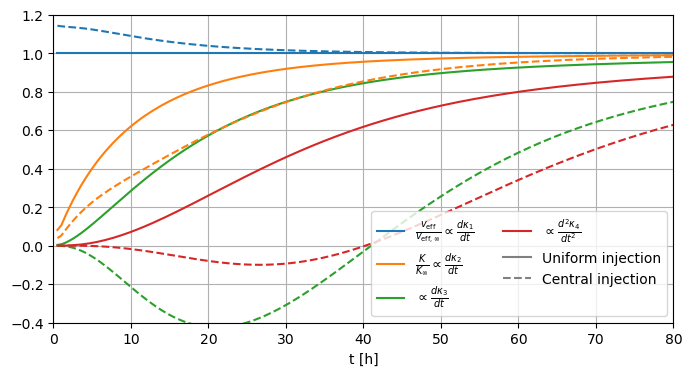

In [62]:
from matplotlib.lines import Line2D
fig,ax = plt.subplots(figsize=(8,4))
def mom_der_over2(p):
    if p%2 == 0:
        return sp.special.factorial(p)*mu**p*(np.sum(-(M_2[0][1:])**2/vals_[1:]))**(p/2)
    else:
        return sp.special.factorial(p)*(p-1)/2*mu**p*(np.sum(-(M_2[0][1:])**2/vals_[1:]))**((p-3)/2)*((M_2[0,1:]/(-vals_[1:]))@M_2[1:,1:]@(M_2[0,1:]/(-vals_[1:]))) 
for i in range(2):
    a0_,b_,v_eff = [a0_dist_,a0_loc_][i],[dm1_coeffs_dist_,dm1_coeffs_loc_][i],[v_eff_dist,v_eff_loc][i]
    D_vals = lambda s: np.diag(1/(s-vals_))
    D_2_vals = lambda s: np.diag(np.diag(b_)*(1-np.eye(N_)[0])/(s-vals_))
    A_0 = lambda s: a0_/(s-vals_)
    section_av_vec = np.nanmean(modes[args_sign],axis = (1,2))
    def sp_cent_moms_lap_func(s,p):
        c_lap = np.zeros(len(s), dtype=complex)
        eigvals = np.zeros((len(s),N_))
        for i,s_i in enumerate(s):
            c_lap[i] = sp.special.factorial(p)*(np.linalg.matrix_power(mu*(D_vals(s_i)@(M_2-D_2_vals(s_i))),p)@A_0(s_i))@section_av_vec
        return c_lap
    m2_der = np.gradient(invlap(sp_cent_moms_lap_func, ts[1:], [2]),ts[1:])
    m3_der = np.gradient(invlap(sp_cent_moms_lap_func, ts[1:], [3]),ts[1:])
    kappa4_der = np.gradient(invlap(sp_cent_moms_lap_func, ts[1:], [4])-3*invlap(sp_cent_moms_lap_func, ts[1:], [2])**2,ts[1:],edge_order = 2)
    print(m2_der[-1],mom_der_over2(2))
    print(m3_der[-1],mom_der_over2(3))
    if i == 0:
        ax.plot(ts[1:]*b**2/D_ref/3600,v_eff, c = 'tab:blue',label = r'$\frac{v_{\text{eff}}}{v_{\text{eff},\infty}} \propto \frac{d \kappa_1}{dt}$')
        ax.plot(ts[1:]*b**2/D_ref/3600,m2_der/m2_der[-1], c = 'tab:orange',label = r'$\frac{K}{K_{\infty}} \propto \frac{d \kappa_2}{dt}$')
        ax.plot(ts[1:]*b**2/D_ref/3600,m3_der/m3_der[-1], c = 'tab:green',label = r'$\propto \frac{d \kappa_3}{dt}$')
        ax.plot(ts[1:]*b**2/D_ref/3600,kappa4_der/kappa4_der[-1], c = 'tab:red',label = r'$\propto \frac{d^2 \kappa_4}{dt^2}$')
    if i == 1:
        ax.plot(ts[1:]*b**2/D_ref/3600,v_eff, c = 'tab:blue',linestyle = 'dashed')
        ax.plot(ts[1:]*b**2/D_ref/3600,m2_der/m2_der[-1], c = 'tab:orange',linestyle = 'dashed')
        ax.plot(ts[1:]*b**2/D_ref/3600,m3_der/m3_der[-1], c = 'tab:green',linestyle = 'dashed')
        ax.plot(ts[1:]*b**2/D_ref/3600,kappa4_der/kappa4_der[-1], c = 'tab:red',linestyle = 'dashed')
ax.grid()
ax.set_xlabel('t [h]')
handles, labels = ax.get_legend_handles_labels()


ax.set_ylim(-0.4,1.2)
ax.set_xlim(0,80)

In [63]:
(b**2/D_ref/3600)/(4*np.pi**2)

np.float64(12.952447162943502)

In [64]:
def sp_moms_lap_func(s,p):
    c_lap = np.zeros(len(s), dtype=complex)
    eigvals = np.zeros((len(s),N_))
    for i,s_i in enumerate(s):
        c_lap[i] = sp.special.factorial(p)*(np.linalg.matrix_power(mu*(D_vals(s_i)@(M_2_adv-D_2_vals(s_i))),p)@A_0(s_i))@section_av_vec
    return c_lap

In [65]:
invlap(sp_cent_moms_lap_func, ts[1:], [3])[-1]/invlap(sp_cent_moms_lap_func, ts[1:], [2])[-1]**(3/2)

np.float64(-0.15357566769557682)

In [66]:
((M_2[0,1:]/(vals_[1:]))@M_2[1:,1:]@(M_2[0,1:]/(vals_[1:])))/np.sum(-(M_2[0][1:])**2/vals_[1:])**(3/2)

np.float64(-0.2211665183730518)

In [67]:
np.linalg.eigvals(M_2[1:,1:])

array([ 0.13938271,  0.10023188,  0.07896158,  0.02992803, -0.00598073,
       -0.12232305, -0.26952691, -0.21654878, -0.35527109, -0.49655754,
       -0.59509739, -0.73626793, -0.80478676, -0.88776466, -0.98944043,
       -0.98237948, -0.97036131, -0.92306195, -0.9406364 ])

In [68]:
np.linalg.eigvals(M_2[1:,1:])

array([ 0.13938271,  0.10023188,  0.07896158,  0.02992803, -0.00598073,
       -0.12232305, -0.26952691, -0.21654878, -0.35527109, -0.49655754,
       -0.59509739, -0.73626793, -0.80478676, -0.88776466, -0.98944043,
       -0.98237948, -0.97036131, -0.92306195, -0.9406364 ])

(-3.0, 1.0)

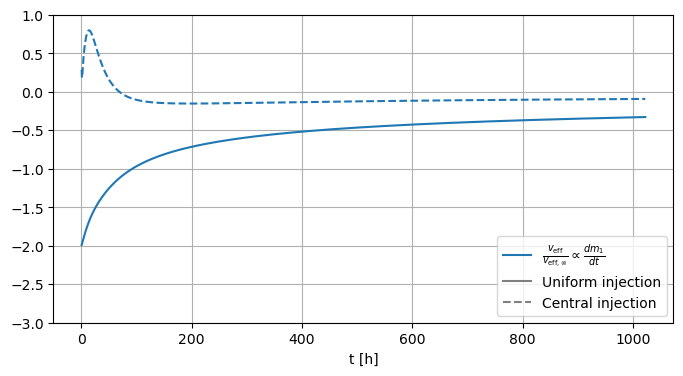

In [69]:
fig,ax = plt.subplots(figsize=(8,4))
ts_long = np.linspace(0,2.0,2000)
for i in range(2):
    a0,dm1_coeffs,v_eff = [a0_dist,a0_loc][i],[dm1_coeffs_dist,dm1_coeffs_loc][i],[v_eff_dist,v_eff_loc][i]
    vecs_ = vecs[:,args_sign]
    vals_ = vals[args_sign]
    b_ = dm1_coeffs[args_sign] 
    a0_ = a0[args_sign] 
    M_1 = vecs_.T@(vecs_*psi_x.T[idx >= 0][:,None]*w)
    M_2 = vecs_.T@(vecs_*(chi).T[idx >= 0][:,None]*w)
    D_vals = lambda s: np.diag(1/(s-vals_))
    D_2_vals = lambda s: np.diag(np.diag(b_)*(1-np.eye(N_)[0])/(s-vals_))
    A_0 = lambda s: a0_/(s-vals_)
    section_av_vec = np.nanmean(modes[args_sign],axis = (1,2))
    def mi_func(s,p):
        c_lap = np.zeros(len(s), dtype=complex)
        eigvals = np.zeros((len(s),N_))
        for i,s_i in enumerate(s):
            c_lap[i] = sp.special.factorial(p)*(np.linalg.matrix_power(mu*(D_vals(s_i)@(M_2-D_2_vals(s_i))),p)@A_0(s_i))@section_av_vec
        return c_lap
    if i == 0:
        ax.plot(ts_long[1:]*b**2/D_ref/3600,invlap(mi_func, ts_long[1:], [3])/invlap(mi_func, ts_long[1:], [2])**(3/2), c = 'tab:blue',label = r'$\frac{v_{\text{eff}}}{v_{\text{eff},\infty}} \propto \frac{d m_1}{dt}$')
    if i == 1:
        ax.plot(ts_long[1:]*b**2/D_ref/3600,invlap(mi_func, ts_long[1:], [3])/invlap(mi_func, ts_long[1:], [2])**(3/2), c = 'tab:blue',linestyle = 'dashed')
ax.grid()
ax.set_xlabel('t [h]')
handles, labels = ax.get_legend_handles_labels()
handles += [Line2D([0],[0],c='gray'),Line2D([0],[0],c='gray',linestyle = 'dashed')]
labels+=['Uniform injection','Central injection']
ax.legend(handles, labels)
ax.set_ylim(-3,1)

In [70]:
init_condition = 'distributed'#'local'#
if init_condition == 'distributed':
    i = 0
if init_condition == 'local':
    i==1
a0,dm1_coeffs,v_eff = [a0_dist,a0_loc][i],[dm1_coeffs_dist,dm1_coeffs_loc][i],[v_eff_dist,v_eff_loc][i]
vecs_ = vecs[:,args_sign]
vals_ = vals[args_sign]
b_ = dm1_coeffs[args_sign] 
a0_ = a0[args_sign] 
M_1 = vecs_.T@(vecs_*psi_x.T[idx >= 0][:,None]*w)
M_2 = vecs_.T@(vecs_*(chi).T[idx >= 0][:,None]*w)
D_vals = lambda s: np.diag(1/(s-vals_))
D_2_vals = lambda s: np.diag(np.diag(b_)*(1-np.eye(N_)[0])/(s-vals_))
A_0 = lambda s: a0_/(s-vals_)
section_av_vec = np.nanmean(modes[args_sign],axis = (1,2))

# Concentration distributions

In [71]:
a0_ = a0_dist_#a0_loc_#
ts_field = np.linspace(0.01,0.75,1500)
Nxi = 2000
xi_max =  80*1000/b
xi_min =  -280*1000/b
dxi = (xi_max-xi_min)/Nxi
padding_factor = 4

In [72]:
%%time
output_length = xi_max - xi_min
L_four = padding_factor * output_length
N_four = int(np.ceil(L_four / dxi))
N_four = 2**int(np.ceil(np.log2(N_four)))
dxi_new = L_four / N_four
dtheta = 2*np.pi / L_four
theta = (np.arange(N_four) - N_four//2) * dtheta

matrix_CF = (np.diag(vals_)
        - theta[:,None,None]**2 * M_1
        + 1j * theta[:,None,None] * mu * M_2)
exp_eigvals,exp_eigfuncs = np.linalg.eig(matrix_CF)
exp_eigfuncs_inv = np.linalg.inv(exp_eigfuncs)

E = np.exp(exp_eigvals*ts_field[:,None,None])
CF_result = (exp_eigfuncs[None, :, :, :]
    @ (E[..., None] * (exp_eigfuncs_inv @ a0_[..., None]))
)[...,0]

Fspace_conc = CF_result[...,0]*a0_[0]

conc_field = np.fft.fftshift(
    np.fft.fft(
        np.fft.ifftshift(Fspace_conc, axes=1),
        axis=1
    ),
    axes=1
).real* dtheta / (2*np.pi)
xis = (np.arange(N_four) - N_four//2) * dxi_new

mask = (xis >= xi_min) & (xis <= xi_max)
xis = xis[mask]
conc_field = conc_field[:,mask]

CPU times: total: 25.4 s
Wall time: 24.8 s


Text(0, 0.5, '$\\tau$')

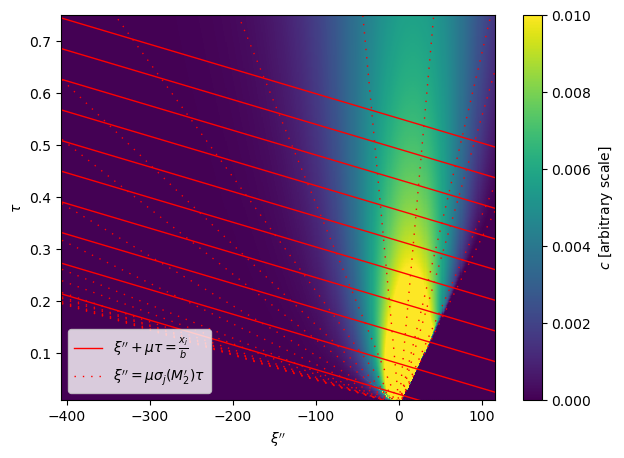

In [73]:
fig,ax = plt.subplots(figsize=(7,5))
pcm = ax.pcolormesh(xis[::5],ts_field[::5],conc_field[::5,::5],vmin = 0,vmax = 0.01)#10**-7)#
fig.colorbar(pcm, label=r'$c$ [arbitrary scale]')
for xi_p in np.linspace(30,800,10)*1000/b:
    ax.plot(xis[(xi_p-xis)/mu>0],((xi_p-xis)/mu)[(xi_p-xis)/mu>0],c = 'r', linewidth = 1)
ax.set_ylim(np.min(ts_field),np.max(ts_field))
for i in np.linalg.eig(M_2)[0]:
    ax.plot(xis,xis/i/mu,c = 'r', linestyle = (0, (1, 5)), linewidth = 1)
handles = [Line2D([0],[0],c = 'r', linewidth = 1),Line2D([0],[0],c = 'r', linestyle = (0, (1, 5)), linewidth = 1)]
labels = [r"$\xi''+\mu\tau=\frac{x_j}{b}$",r"$\xi''=\mu\sigma_j(M_2')\tau$"]
ax.legend(handles, labels,loc='lower left')
ax.set_xlabel(r"$\xi''$")
ax.set_ylabel(r"$\tau$")

In [74]:
from scipy.interpolate import RegularGridInterpolator
interpolator = RegularGridInterpolator(
    (ts_field, xis),
    conc_field,
    bounds_error=False,
    fill_value=0.0
)

(0.0, 0.3)

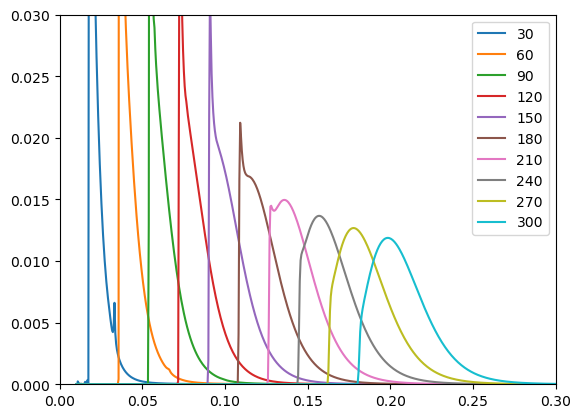

In [75]:
for x_p in np.linspace(30,300,10):
    xi_p = x_p*1000/b
    plt.plot(ts_field,interpolator(np.array([ts_field,xi_p-ts_field*mu]).T), label = int(x_p))
plt.legend()
plt.ylim(0,0.03)
plt.xlim(0,0.3)

In [76]:
xs_btc = np.linspace(-10,800,1000)
btcs = np.zeros((len(xs_btc),len(ts_field)))
xis_btc = xs_btc*1000/b
for i,xi_p in enumerate(xis_btc):
    btcs[i] = interpolator(np.array([ts_field,xi_p-ts_field*mu]).T)

In [77]:
m0_btcs = np.trapezoid(btcs,x= ts_field,axis = 1)
m1_btcs = np.trapezoid(btcs*ts_field,x= ts_field,axis = 1)/m0_btcs
m2_btcs = np.trapezoid(btcs*(ts_field-m1_btcs[:,None])**2,x= ts_field,axis = 1)/m0_btcs
m3_btcs = np.trapezoid(btcs*(ts_field-m1_btcs[:,None])**3,x= ts_field,axis = 1)/m0_btcs
print(m3_btcs[-1])
kappa4_btcs = np.trapezoid(btcs*(ts_field-m1_btcs[:,None])**4,x= ts_field,axis = 1)/m0_btcs-3*m2_btcs**2

2.072420228951131e-05


In [78]:
mu1_btcs = np.trapezoid(btcs*ts_field,x= ts_field,axis = 1)/m0_btcs
mu2_btcs = np.trapezoid(btcs*(ts_field)**2,x= ts_field,axis = 1)/m0_btcs
mu3_btcs = np.trapezoid(btcs*(ts_field)**3,x= ts_field,axis = 1)/m0_btcs
mu4_btcs = np.trapezoid(btcs*(ts_field)**4,x= ts_field,axis = 1)/m0_btcs

In [79]:
max_vel = ((max(np.linalg.eig(M_2)[0])+1)*mu)

(0.01, 0.75)

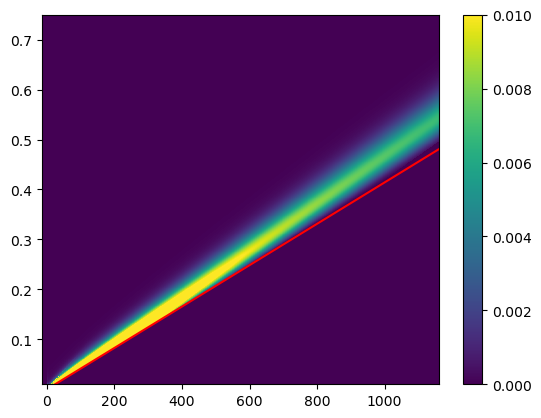

In [80]:
plt.pcolormesh(xis_btc,ts_field,btcs.T,vmin = 0,vmax = 0.01)
plt.plot(xis_btc,xis_btc/max_vel,c = 'r')
plt.colorbar()
plt.ylim(min(ts_field),max(ts_field))

In [81]:
m0_sp_btcs = np.trapezoid(btcs[:,ts_field<xis_btc[-1]/max_vel],x = xis_btc,axis = 0)
m1_sp_btcs = np.trapezoid(btcs[:,ts_field<xis_btc[-1]/max_vel]*xis_btc[:,None],x = xis_btc,axis = 0)/m0_sp_btcs
m2_sp_btcs = np.trapezoid(btcs[:,ts_field<xis_btc[-1]/max_vel]*(xis_btc[:,None]-m1_sp_btcs)**2,x = xis_btc,axis = 0)/m0_sp_btcs
m3_sp_btcs = np.trapezoid(btcs[:,ts_field<xis_btc[-1]/max_vel]*(xis_btc[:,None]-m1_sp_btcs)**3,x = xis_btc,axis = 0)/m0_sp_btcs

(1, 10)

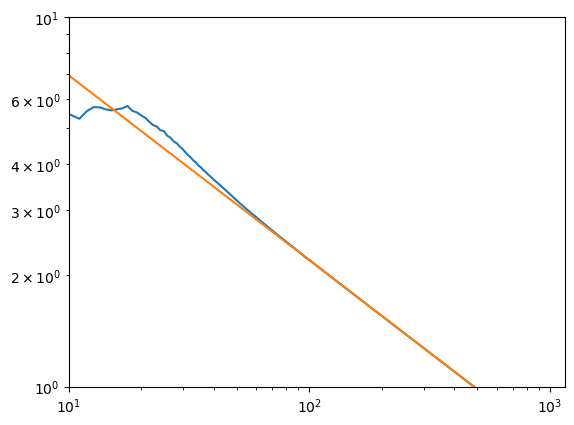

In [82]:
plt.loglog(xs_btc[xs_btc>0],(m3_btcs/m2_btcs**(3/2))[xs_btc>0])
plt.loglog(xs_btc[xs_btc>0],(xs_btc**(-1/2)*22)[xs_btc>0])
plt.xlim(10,None)
plt.ylim(1,10)

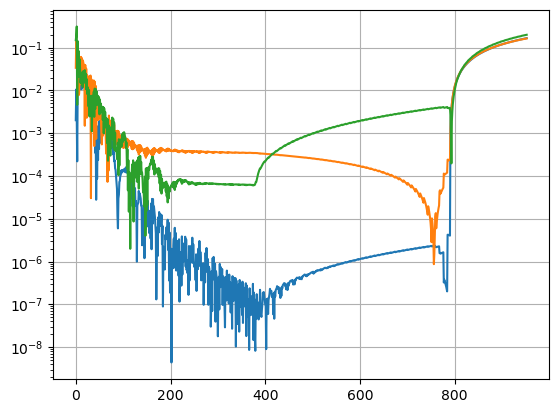

In [83]:
plt.semilogy(np.abs(1-np.interp(ts_field[ts_field<xis_btc[-1]/max_vel],ts[1:],invlap(sp_moms_lap_func, ts[1:], [1]))/m1_sp_btcs))
plt.semilogy(np.abs(1-np.interp(ts_field[ts_field<xis_btc[-1]/max_vel],ts[1:],invlap(sp_cent_moms_lap_func, ts[1:], [2]))/m2_sp_btcs))
plt.semilogy(np.abs(1-np.interp(ts_field[ts_field<xis_btc[-1]/max_vel],ts[1:],invlap(sp_cent_moms_lap_func, ts[1:], [3]))/m3_sp_btcs))
plt.grid()

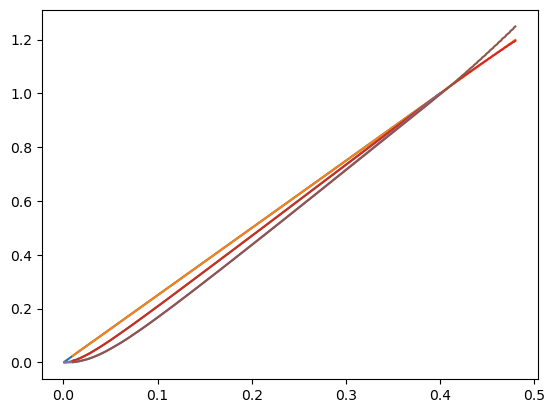

In [84]:
plt.plot(ts[1:],invlap(sp_moms_lap_func, ts[1:], [1])/invlap(sp_moms_lap_func, ts[1:], [1])[-1])
plt.plot(ts_field[ts_field<xis_btc[-1]/max_vel],m1_sp_btcs/invlap(sp_moms_lap_func, ts[1:], [1])[-1])

plt.plot(ts[1:],invlap(sp_cent_moms_lap_func, ts[1:], [2])/invlap(sp_cent_moms_lap_func, ts[1:], [2])[-1])
plt.plot(ts_field[ts_field<xis_btc[-1]/max_vel],m2_sp_btcs/invlap(sp_cent_moms_lap_func, ts[1:], [2])[-1])

plt.plot(ts[1:],invlap(sp_cent_moms_lap_func, ts[1:], [3])/invlap(sp_cent_moms_lap_func, ts[1:], [3])[-1])
plt.plot(ts_field[ts_field<xis_btc[-1]/max_vel],m3_sp_btcs/invlap(sp_cent_moms_lap_func, ts[1:], [3])[-1])

# Asymptotic matching of moment

In [85]:
import numpy as np
from scipy.linalg import eig

def theta_star_Q3D_ADE(s):
    
    A = np.diag(1.0 / (vals_[1:] - s))

    n = N_-1

    C = np.zeros((n+1, n+1), dtype=complex)
    C[0, 0] = s
    C[1:, 1:] = np.eye(n)

    D = np.zeros((n+1, n+1), dtype=complex)
    D[0, 0] = 1.0
    D[0, 1:] = M_2_adv[0,1:]
    D[1:, 0] = -A @ M_2_adv[1:,0]
    D[1:, 1:] = -M_2_adv[1:,1:] @ A

    lam = eig(C, -D, right=False)

    theta = lam/mu

    return theta[np.argmax(theta.real)].real


In [86]:
s_s = np.linspace(-0.01,0.01,1001)
theta_star = [theta_star_Q3D_ADE(s) for s in s_s]

In [87]:
import numdifftools as nd
moms_der_Q3D_ADE = lambda N_cums: np.array([(-1)**i*nd.Derivative(np.vectorize(theta_star_Q3D_ADE), n=i,order=10)(0.0) for i in range(1,N_cums+1)])
moms_der_Q3D_ADE_2 = moms_der_Q3D_ADE(2)
moms_der_Q3D_ADE_4 = moms_der_Q3D_ADE(4)

ModuleNotFoundError: No module named 'numdifftools'

In [ ]:
from math import factorial
ders_fit = lambda n: np.polyfit(s_s,theta_star,n)[::-1][1:]*np.array([(-1)**i*factorial(i) for i in range(1,n+1)])
ders_fit(4),moms_der_Q3D_ADE(4)

In [ ]:
plt.plot(np.gradient(m3_btcs,xis_btc)[-100:])
moms_der_Q3D_ADE_4[2]

In [ ]:
plt.plot(np.gradient(kappa4_btcs,xis_btc)[-100:])
moms_der_Q3D_ADE_4[3]

In [ ]:
from scipy.optimize import differential_evolution
from scipy.optimize import minimize
v = mu
D = K_lim
k_f_over_k_r = np.max(np.linalg.eig(M_2)[0])
k_r = 50

In [ ]:
def g_lap(s,pars,N_rates):
    if N_rates == 0:
        return np.zeros_like(s)
    else:
        return sum([pars[2*i]*pars[2*i+1]/(pars[2*i+1]+s) for i in range(N_rates)])
def theta_star_MFE (s,pars,N_rates): 
    if N_rates == 0:
        A1 = 1
        A2 = 0
    else:
        A1 = 1+np.sum(pars[::2])
        A2 = 2*np.sum(pars[::2]/pars[1::2])
    v = A1/moms_der_Q3D_ADE_2[0]
    D = (moms_der_Q3D_ADE_2[1]-A2/v)*v**3/(2*A1**2)
    return 1/(2*D)*(v-np.sqrt(v**2+4*s*(1+g_lap(s,pars,N_rates))*D))
moms_der_MFE = lambda pars,N_rates,N_cums: np.array([(-1)**i*nd.Derivative(np.vectorize(lambda s: theta_star_MFE(s,pars,N_rates)), n=i)(0.0) for i in range(1,N_cums+1)])
def loss(par,N_rates,moms_der_Q3D_ADE_i):
    N_cums = 2+2*N_rates
    ratio = moms_der_MFE(par,N_rates,N_cums)/moms_der_Q3D_ADE_i
    return np.sum((np.sign(ratio)*np.abs(ratio)**(1/np.arange(1,N_cums+1))-1)**2)

In [ ]:
def estimate_parameters_MFE(N_rates = 1):
    if N_rates == 0:
        return []
    else:
        pars_0 = np.array([k_f_over_k_r/N_rates if i%2==0 else k_r for i in range(2*N_rates)])
        print(pars_0)
        bounds = [(0,np.max(np.linalg.eig(M_2)[0])/N_rates) if i%2==0 else (k_r/20,k_r*20) for i in range(2*N_rates)]
        # moms_der_Q3D_ADE_i = np.array([np.polyfit(xis_btc[-100:],m1_btcs[-100:],1)[0],
        #                                np.polyfit(xis_btc[-100:],m2_btcs[-100:],1)[0],
        #                                np.polyfit(xis_btc[-100:],m3_btcs[-100:],1)[0],
        #                                np.polyfit(xis_btc[-100:],kappa4_btcs[-100:],1)[0]])
        moms_der_Q3D_ADE_i = moms_der_Q3D_ADE(2+2*N_rates)
        print(loss(pars_0,N_rates,moms_der_Q3D_ADE_i))
        opt_result_0 = differential_evolution(lambda par: loss(par,N_rates,moms_der_Q3D_ADE_i), bounds,maxiter=500, popsize=20, seed = 42)
        print(loss(opt_result_0.x,N_rates,moms_der_Q3D_ADE_i))
        opt_result_1 = minimize(lambda par: loss(par,N_rates,moms_der_Q3D_ADE_i), opt_result_0.x, method='Nelder-Mead', bounds = bounds,
                         options={'xatol': 1e-3, 'fatol': 1e-3})
        print(loss(opt_result_1.x,N_rates,moms_der_Q3D_ADE_i))
        opt_result_2 = minimize(lambda par: loss(par,N_rates,moms_der_Q3D_ADE_i), opt_result_1.x, method='Nelder-Mead', bounds = bounds,
                         options={'xatol': 1e-5, 'fatol': 1e-5})
        print(loss(opt_result_2.x,N_rates,moms_der_Q3D_ADE_i))
        return opt_result_2.x

In [ ]:
%%time
params_MFE_0 = estimate_parameters_MFE(0)
print(params_MFE_0)
params_MFE_1 = estimate_parameters_MFE(1)
print(params_MFE_1)
# params_MFE_2 = estimate_parameters_MFE(2)
# print(params_MFE_2)

In [ ]:
params_MFE_1/np.array([k_f_over_k_r,k_r])

In [ ]:
# params_MFE_2/np.array([k_f_over_k_r,k_r,k_f_over_k_r,k_r])

In [ ]:
[format(i,'.1%') for i in moms_der_MFE(params_MFE_0,0,6)/moms_der_Q3D_ADE(6)-1]

In [ ]:
[format(i,'.1%') for i in moms_der_MFE(params_MFE_1,1,6)/moms_der_Q3D_ADE(6)-1]

In [ ]:
moms_der_MFE(params_MFE_1,1,4)/np.array([np.polyfit(xis_btc[-100:],m1_btcs[-100:],1)[0],
                                       np.polyfit(xis_btc[-100:],m2_btcs[-100:],1)[0],
                                       np.polyfit(xis_btc[-100:],m3_btcs[-100:],1)[0],
                                       np.polyfit(xis_btc[-100:],kappa4_btcs[-100:],1)[0]])

In [ ]:
fig,ax = plt.subplots(figsize=(7,5))
def MFE(s,xi,pars,N_rates):
    if N_rates == 0:
        A1 = 1
        A2 = 0
    else:
        A1 = 1+np.sum(pars[::2])
        A2 = 2*np.sum(pars[::2]/pars[1::2])
    v = A1/moms_der_Q3D_ADE_2[0]
    D = (moms_der_Q3D_ADE_2[1]-A2/v)*v**3/(2*A1**2)
    c_lap = np.exp(xi/(2*D)*(v-np.sqrt(v**2+4*s*(1+g_lap(s,pars,N_rates))*D)))
    return c_lap
for i,x_p in enumerate(np.linspace(480,800,3)):
    xi_p = x_p*1000/b
    indx_x = np.argmin(np.abs(xi_p-xis_btc))
    ax.plot(ts_field*b**2/D_ref/3600,btcs[indx_x], label = str(int(x_p))+' km', c = colors[i])
    btc_MFE_0 = invlap(MFE, ts_field,[xis_btc[indx_x],params_MFE_0,0])
    ax.plot(ts_field*b**2/D_ref/3600,btc_MFE_0/np.trapezoid(btc_MFE_0[~np.isnan(btc_MFE_0)],(ts_field*b**2/D_ref/3600)[~np.isnan(btc_MFE_0)])*np.trapezoid(btcs[indx_x],ts_field*b**2/D_ref/3600), 
            c = colors[i], linestyle = 'dotted')
    btc_MFE_1 = invlap(MFE, ts_field,[xis_btc[indx_x],params_MFE_1,1])
    ax.plot(ts_field*b**2/D_ref/3600,btc_MFE_1/np.trapezoid(btc_MFE_1[~np.isnan(btc_MFE_1)],(ts_field*b**2/D_ref/3600)[~np.isnan(btc_MFE_1)])*np.trapezoid(btcs[indx_x],ts_field*b**2/D_ref/3600),
            c = colors[i], linestyle = 'dashed')
    # btc_MFE_2 = invlap(MFE, ts_field,[xis_btc[indx_x],params_MFE_2,2])
    # plt.plot(ts_field*b**2/D_ref/3600,btc_MFE_2/np.trapezoid(btc_MFE_2[~np.isnan(btc_MFE_2)],(ts_field*b**2/D_ref/3600)[~np.isnan(btc_MFE_2)])*np.trapezoid(btcs[indx_x],ts_field*b**2/D_ref/3600),
    #          c = colors[i], linestyle = 'dashdot')
handles, labels = ax.get_legend_handles_labels()
handles += [Line2D([0],[0],c='gray'),Line2D([0],[0],c='gray', linestyle = 'dotted'),Line2D([0],[0],c='gray',linestyle = 'dashed'),Line2D([0],[0],c='gray',linestyle = 'dashdot')]
labels+=['Q3D-ADE','Asym. 1D-ADE','Asym. 1D-FO-MFE']#,'Asym. 1D-MRMT, 2 rates']
ax.legend(handles, labels, ncols = 2)
ax.grid()
ax.set_ylim(0,0.01)
ax.set_xlim(140,340)
ax.set_ylabel('$c$')
ax.set_xlabel('$t$ [h]')

In [ ]:
[[format(j-1,'.1%') for j in i] for i in [moms_der_MFE(params_MFE_0,0,6)/moms_der_Q3D_ADE(6),moms_der_MFE(params_MFE_1,1,6)/moms_der_Q3D_ADE(6),moms_der_MFE(params_MFE_2,2,6)/moms_der_Q3D_ADE(6)]]

In [ ]:
x_p = 150
xi_p = x_p*1000/b
indx_x = np.argmin(np.abs(xi_p-xis_btc))

In [ ]:
m0_MFE_0 = np.trapezoid(btc_MFE_0[~np.isnan(btc_MFE_0)])
m1_MFE_0 = np.trapezoid(btc_MFE_0[~np.isnan(btc_MFE_0)]*ts_field[~np.isnan(btc_MFE_0)])/m0_MFE_0
m2_MFE_0 = np.trapezoid(btc_MFE_0[~np.isnan(btc_MFE_0)]*(ts_field[~np.isnan(btc_MFE_0)]-m1_MFE_0)**2)/m0_MFE_0
m3_MFE_0 = np.trapezoid(btc_MFE_0[~np.isnan(btc_MFE_0)]*(ts_field[~np.isnan(btc_MFE_0)]-m1_MFE_0)**3)/m0_MFE_0

m0_MFE_1 = np.trapezoid(btc_MFE_1[~np.isnan(btc_MFE_1)])
m1_MFE_1 = np.trapezoid(btc_MFE_1[~np.isnan(btc_MFE_1)]*ts_field[~np.isnan(btc_MFE_1)])/m0_MFE_1
m2_MFE_1 = np.trapezoid(btc_MFE_1[~np.isnan(btc_MFE_1)]*(ts_field[~np.isnan(btc_MFE_1)]-m1_MFE_1)**2)/m0_MFE_1
m3_MFE_1 = np.trapezoid(btc_MFE_1[~np.isnan(btc_MFE_1)]*(ts_field[~np.isnan(btc_MFE_1)]-m1_MFE_1)**3)/m0_MFE_1

m0_MFE_2 = np.trapezoid(btc_MFE_2[~np.isnan(btc_MFE_2)])
m1_MFE_2 = np.trapezoid(btc_MFE_2[~np.isnan(btc_MFE_2)]*ts_field[~np.isnan(btc_MFE_2)])/m0_MFE_2
m2_MFE_2 = np.trapezoid(btc_MFE_2[~np.isnan(btc_MFE_2)]*(ts_field[~np.isnan(btc_MFE_2)]-m1_MFE_2)**2)/m0_MFE_2
m3_MFE_2 = np.trapezoid(btc_MFE_2[~np.isnan(btc_MFE_2)]*(ts_field[~np.isnan(btc_MFE_2)]-m1_MFE_2)**3)/m0_MFE_2

In [ ]:
[format(i,'.1%') for i in (1-np.array([np.mean(np.gradient(m1_btcs,xis_btc)[-100:]),
          np.mean(np.gradient(m2_btcs,xis_btc)[-100:]),
          np.mean(np.gradient(m3_btcs,xis_btc)[-100:]),
          np.mean(np.gradient(kappa4_btcs,xis_btc)[-100:])])/moms_der_Q3D_ADE(4))]

In [ ]:
moms_der_Q3D_ADE(4)

In [ ]:
[[format(j-1,'.2%') for j in i] for i in [[m1_MFE_0/m1_btcs[indx_x],m2_MFE_0/m2_btcs[indx_x],m3_MFE_0/m3_btcs[indx_x]],
                           [m1_MFE_1/m1_btcs[indx_x],m2_MFE_1/m2_btcs[indx_x],m3_MFE_1/m3_btcs[indx_x]],
                           [m1_MFE_2/m1_btcs[indx_x],m2_MFE_2/m2_btcs[indx_x],m3_MFE_2/m3_btcs[indx_x]]]]

# Temporal moments

In [135]:
xs_tm = np.linspace(0,200,3000)
xis_tm = xs_tm*1000/b

In [136]:
def raw_moment(inv_mat,p):
    return sp.special.factorial(p)*(np.linalg.matrix_power(inv_mat,p+1)@a0_)@section_av_vec

def mi_func_t(theta,p):
    c_lap = np.zeros(len(theta), dtype=complex)
    for i,theta_i in enumerate(theta):
        inv_mat = np.linalg.inv(
            theta_i**2*M_1
            -theta_i*mu*M_2_adv+np.diag(vals_))
        c_lap[i] = raw_moment(inv_mat,p)
    return c_lap

(0.0, 30.0)

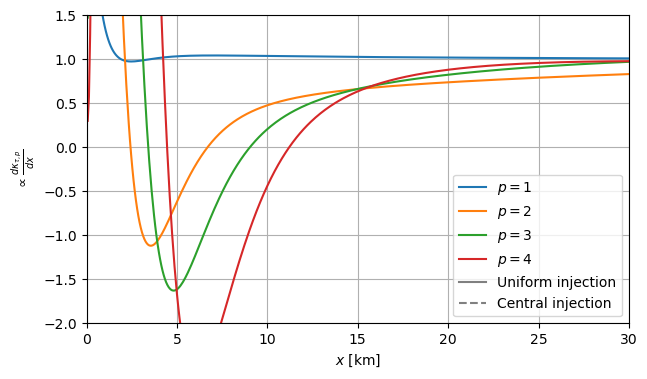

In [157]:
fig,ax = plt.subplots(figsize=(7,4))
for i in range(1):
    a0,dm1_coeffs,v_eff = [a0_dist,a0_loc][i],[dm1_coeffs_dist,dm1_coeffs_loc][i],[v_eff_dist,v_eff_loc][i]
    vecs_ = vecs[:,args_sign]
    vals_ = vals[args_sign]
    b_ = dm1_coeffs[args_sign] 
    a0_ = a0[args_sign] 
    M_1 = vecs_.T@(vecs_*psi_x.T[idx >= 0][:,None]*w)
    M_2 = vecs_.T@(vecs_*(chi).T[idx >= 0][:,None]*w)
    D_vals = lambda s: np.diag(1/(s-vals_))
    D_2_vals = lambda s: np.diag(np.diag(b_)*(1-np.eye(N_)[0])/(s-vals_))
    A_0 = lambda s: a0_/(s-vals_)
    section_av_vec = np.nanmean(modes[args_sign],axis = (1,2))
    
    m1_t_pos = invlap(mi_func_t, xis_tm[xis_tm>0], [1])*mu
    m1_t_grad = np.gradient(m1_t_pos,xis_tm[xis_tm>0])
    m2_t_pos =  -invlap(mi_func_t, xis_tm[xis_tm>0], [2])*mu
    m2_t_cent = m2_t_pos-m1_t_pos**2
    m2_t_cent_grad = np.gradient(m2_t_cent,xis_tm[xis_tm>0])
    m3_t_pos =  invlap(mi_func_t, xis_tm[xis_tm>0], [3])*mu
    m3_t_cent = m3_t_pos-3*m2_t_pos*m1_t_pos+2*m1_t_pos**3
    m3_t_cent_grad = np.gradient(m3_t_cent,xis_tm[xis_tm>0])
    m4_t_pos =  -invlap(mi_func_t, xis_tm[xis_tm>0], [4])*mu
    m4_t_cent = m4_t_pos-4*m3_t_pos*m1_t_pos+6*m2_t_pos*m1_t_pos**2-3*m1_t_pos**4
    kappa_4 = m4_t_cent-3*m2_t_cent**2
    kappa_4_t_cent_grad = np.gradient(kappa_4,xis_tm[xis_tm>0])
    
    plt.plot(xs_tm[xs_tm>0],m1_t_grad/m1_t_grad[-1], c = 'tab:blue',label = r'$p=1$')
    plt.plot(xs_tm[xs_tm>0],m2_t_cent_grad/m2_t_cent_grad[-1], c = 'tab:orange',label = r'$p=2$')
    plt.plot(xs_tm[xs_tm>0],m3_t_cent_grad/m3_t_cent_grad[-1], c = 'tab:green',label = r'$p=3$')
    plt.plot(xs_tm[xs_tm>0],kappa_4_t_cent_grad/kappa_4_t_cent_grad[-1], c = 'tab:red',label = r'$p=4$')
ax.grid()
ax.set_ylabel(r'$\propto\frac{d \kappa_{\tau,p}}{dx}$')
ax.set_xlabel(r'$x$ [km]')
handles, labels = ax.get_legend_handles_labels()
handles += [Line2D([0],[0],c='gray'),Line2D([0],[0],c='gray',linestyle = 'dashed')]
labels+=['Uniform injection','Central injection']
ax.legend(handles, labels)
ax.set_ylim(-2,1.5)
ax.set_xlim(0,30)

In [343]:
### OLD

### Laplace space solution of the concentration distributions

# # %%time
# import numpy as np
# from scipy.linalg import expm, inv, eig

# M_2_adv = vecs_.T@(vecs_*(1+chi).T[idx >= 0][:,None]*w)

# def distribution_lap_with_long_diff(s, x):
#     if np.array(x).size == 1:
#         x = np.array([x])
#         Float = True
#     else:
#         Float = False
#     c_lap = np.zeros((len(s),len(x)), dtype=complex)
#     # c_lap = np.zeros((len(s)), dtype=complex)
#     # Pre-calculate identity
#     I = np.eye(N_)
#     M1_inv = inv(M_1)
    
#     for i, s_i in enumerate(s):
#         # 1. Build the 2n x 2n Companion Matrix H(s)
#         # Top row: [0, I]
#         # Bottom row: [M1^-1 * (sI + Lambda), M1^-1 * mu * M2]
        
#         term_lower_left = M1_inv @ (s_i * I - np.diag(vals_))
#         term_lower_right = M1_inv @ (mu * M_2_adv)
        
#         H = np.block([
#             [np.zeros((N_, N_)), I],
#             [term_lower_left,  term_lower_right]
#         ])
        
#         eigenvalues, P = sp.linalg.eig(H)
        
        
#         # Split by sign of Re(lambda)
#         stable   = np.real(eigenvalues) < 0   # decay for x > 0
#         unstable = np.real(eigenvalues) > 0   # decay for x < 0
        
    
#         P_minus = P[:, stable]     # used for x > 0
#         P_plus  = P[:, unstable]   # used for x < 0
#         L_minus = eigenvalues[stable]
#         L_plus  = eigenvalues[unstable]
    
#         P_minus_f  = P_minus[:n, :]   # (n x n)
#         P_minus_fp = P_minus[n:, :]   # (n x n)
#         P_plus_f   = P_plus[:n, :]    # (n x n)
#         P_plus_fp  = P_plus[n:, :]    # (n x n)
        
#         # Jump system (2n x 2n) ✓
#         jump = np.block([
#             [ P_minus_f,   -P_plus_f  ],   # continuity of f
#             [ P_minus_fp,  -P_plus_fp ]    # jump in f'
#         ])
    
#         # Note: rhs top block is 2n zeros (continuity of f and the delta jump)
#         rhs    = np.concatenate([np.zeros(N_), -M1_inv @ a0[args_sign]])
#         c      = np.linalg.solve(jump, rhs)
#         n_stab = stable.sum()
#         c_minus = c[:n_stab]       # coefficients for x > 0
#         c_plus  = c[n_stab:]       # coefficients for x < 0
        
#         exp_d  = np.exp(L_minus * x[x >= 0][:,None])
#         u_x_plus = P_minus @ (exp_d * c_minus).T
#         exp_d  = np.exp(L_plus * x[x < 0][:,None])
#         u_x_minus    = P_plus  @ (exp_d * c_plus).T
#         c_lap[i] = np.concatenate((section_av_vec @u_x_minus[:N_],section_av_vec @u_x_plus[:N_]))
#     if Float:
#         c_lap = c_lap[:,0]
#     return c_lap

# fig,ax = plt.subplots(figsize=(5,4))
# # To run with your de Hoog inverter:
# xis_disc = np.arange(0,400*1000/b,20)

# m_i_disc = np.zeros((len(xis_disc),6,5))

# min_dets = np.concatenate((10**np.array([-2.0,-3.0,-4.0,-5.0]),[-np.inf]))

# for i,xi in enumerate(xis_disc):#[-20.0,-10.0,0.0,10.0,20.0,30.0,40.0]:
#     btc = invlap(distribution_lap_with_long_diff, ts[1:], [xi])
    
#     for j in range(len(min_dets)):
#         min_det = min_dets[j]
#         m0 = np.trapezoid(btc[btc>min_det*np.max(btc)],ts[1:][btc>min_det*np.max(btc)])
#         m1 = np.trapezoid(btc[btc>min_det*np.max(btc)]*ts[1:][btc>min_det*np.max(btc)],ts[1:][btc>min_det*np.max(btc)])/m0
#         m2 = np.trapezoid(btc[btc>min_det*np.max(btc)]*(ts[1:][btc>min_det*np.max(btc)]-m1)**2,ts[1:][btc>min_det*np.max(btc)])/m0
#         m3 = np.trapezoid(btc[btc>min_det*np.max(btc)]*(ts[1:][btc>min_det*np.max(btc)]-m1)**3,ts[1:][btc>min_det*np.max(btc)])/m0
#         m4 = np.trapezoid(btc[btc>min_det*np.max(btc)]*(ts[1:][btc>min_det*np.max(btc)]-m1)**4,ts[1:][btc>min_det*np.max(btc)])/m0
#         m_i_disc[i,j]=[m0,m1,m2,m3,m4]
#     print(m3/m2**(3/2))
#     plt.plot(ts[1:]*b**2/D_ref/3600, btc, label = fr'$x={{{xi*b/1000:.0f}}}$ km')
# plt.ylim(0,0.05)
# plt.xlabel('t [h]')
# plt.xlim(0,150)
# plt.ylabel(r'$C$')
# plt.grid()
# # plt.legend()